
# Lower Limb Movement Sensing

## Data Processing

This notebook contains the processing and visualization of the strain sensor measurements recorded during the laboratory 2. 






## Lab 2a - Sensor Setup & Data Collection
# 1.1 Setup & Positioning of the sensors


- Two EMG sensors were placed on the quadriceps and calf muscles to measure muscle activity. 

- A resistive strain sensor was positioned across the knee to monitor knee bending.

**Note:** See images in the report


# 1.2 Knee Bending and Strain Sensor Response




In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Fixed Resistor
R1 = 10000  

# Maximum value of 10-bit ADC
max_adc = 1023 

# Convert ADC values to sensor resistance
def adc_to_resistance(adc):
    return R1 * adc / (max_adc - adc)

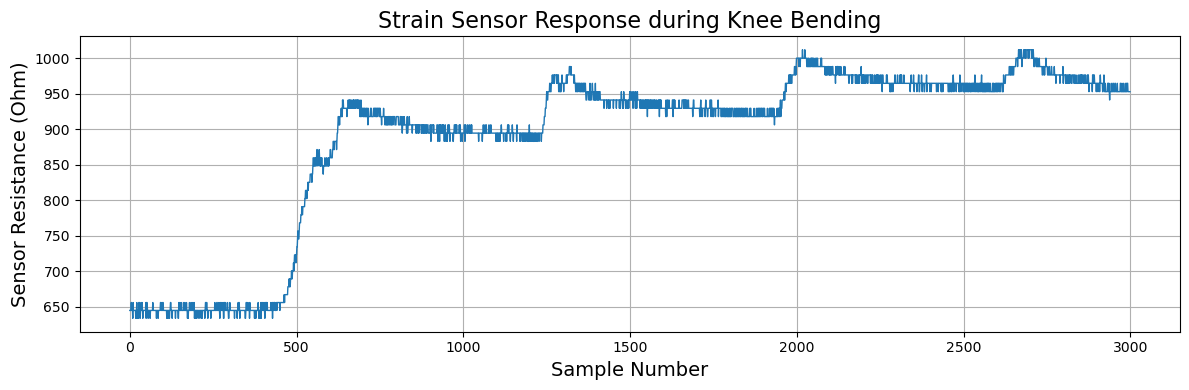

In [16]:
# Load knee bending data
adc_knee = np.loadtxt("ex1.2_check_1.txt", delimiter=",")

# Extract sensor signals
adc_strain = adc_knee[:3000, 0]
emg_quad = adc_knee[:, 1]
emg_calf = adc_knee[:, 2]

# Convert ADC values to sensor resistance
resistance_knee = adc_to_resistance(adc_strain)

# Plot
plt.figure(figsize=(12, 4))
plt.plot(resistance_knee, linewidth=1)

plt.xlabel("Sample Number", fontsize=14)
plt.ylabel("Sensor Resistance (Ohm)", fontsize=14)
plt.title("Strain Sensor Response during Knee Bending", fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.show()

## 1 second == 250 samples


# 1.3 RAW EMG Recordings

### Quad Recording

All three channels from `ex1.3_quad_20sec.txt`, plotted as raw ADC values at 250 Hz.


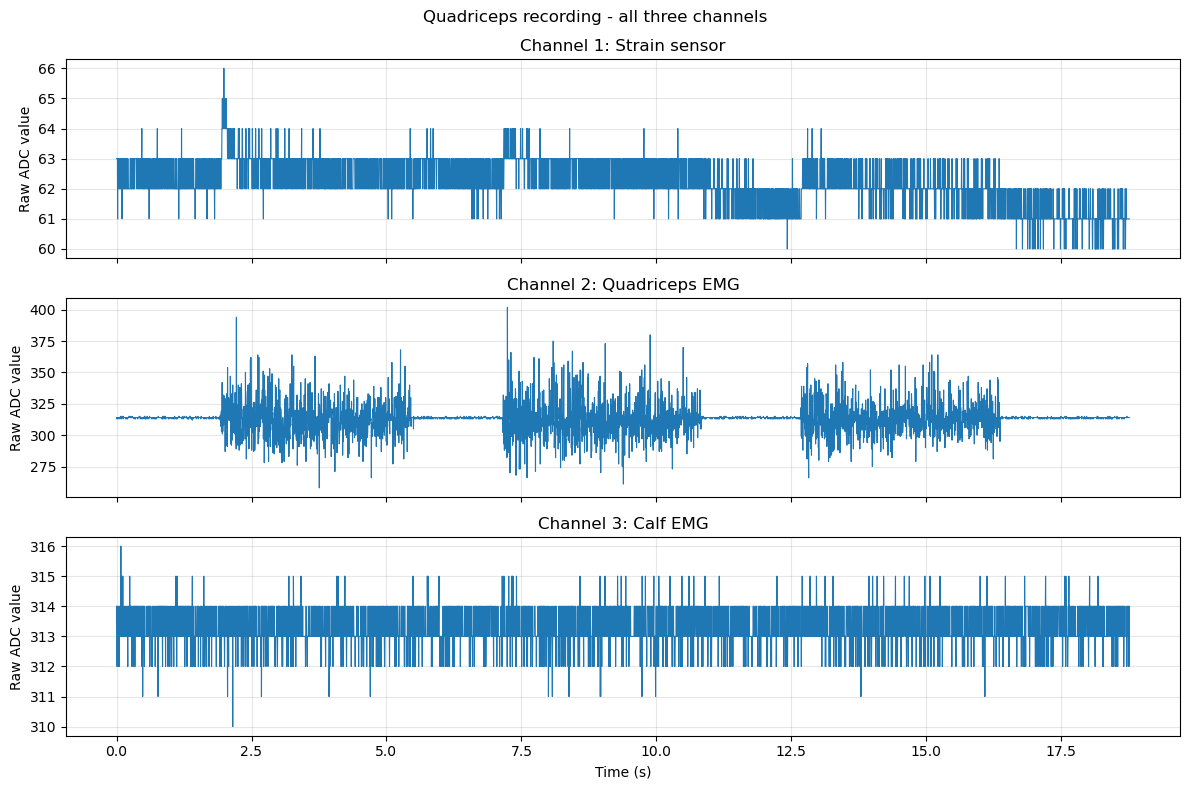

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# Columns: strain sensor, quadriceps EMG, calf EMG (raw ADC values).
quad_data = np.loadtxt("ex1.3_quad_20sec.txt", delimiter=",")
sampling_rate = 250  # Hz: 250 samples per second
time_s = np.arange(quad_data.shape[0]) / sampling_rate

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
channel_names = ["Strain sensor", "Quadriceps EMG", "Calf EMG"]
for channel, (ax, name) in enumerate(zip(axes, channel_names)):
    ax.plot(time_s, quad_data[:, channel], linewidth=0.8)
    ax.set_title(f"Channel {channel + 1}: {name}")
    ax.set_ylabel("Raw ADC value")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (s)")
fig.suptitle("Quadriceps recording - all three channels")
fig.tight_layout()
plt.show()


## Calf recording

All three channels from `ex1.3_calve_20sec_clean.txt`, plotted as raw ADC values at 250 Hz.


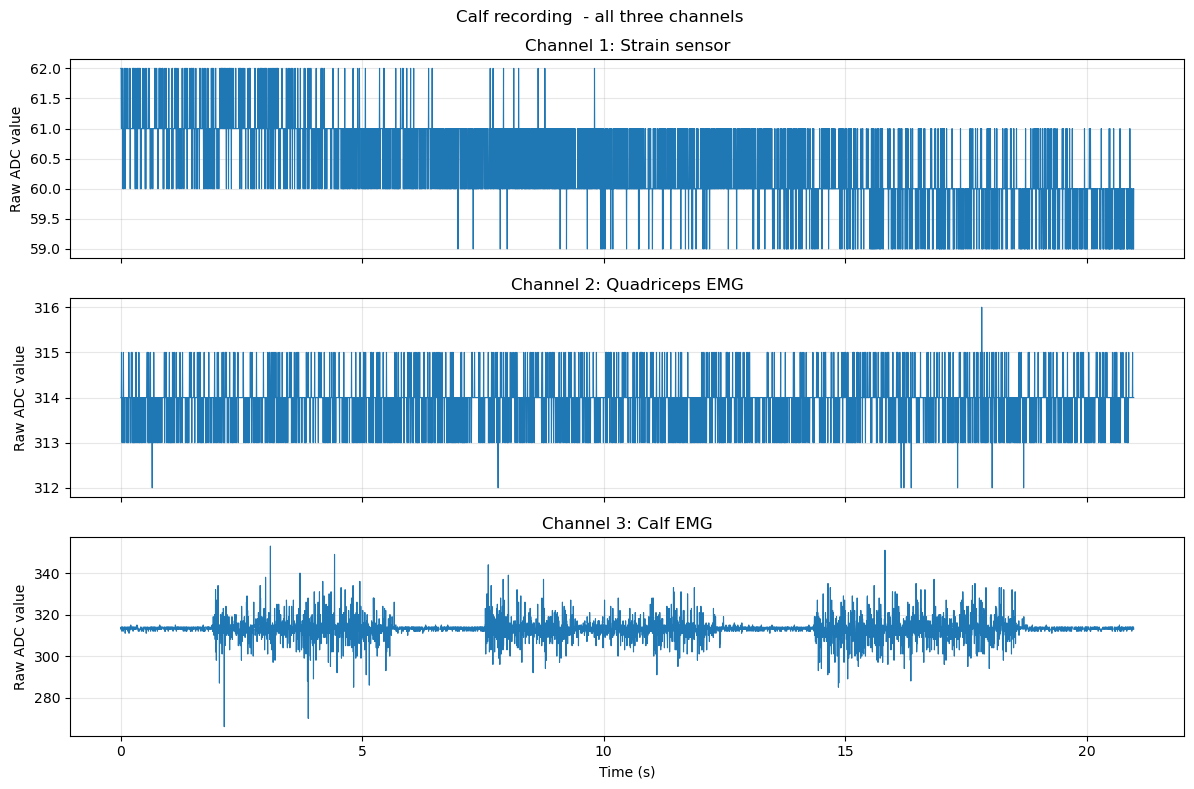

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Columns: strain sensor, quadriceps EMG, calf EMG (raw ADC values).
calf_data = np.loadtxt("ex1.3_calve_20sec_clean.txt", delimiter=",")
sampling_rate = 250  # Hz: 250 samples per second
time_s = np.arange(calf_data.shape[0]) / sampling_rate

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
channel_names = ["Strain sensor", "Quadriceps EMG", "Calf EMG"]
for channel, (ax, name) in enumerate(zip(axes, channel_names)):
    ax.plot(time_s, calf_data[:, channel], linewidth=0.8)
    ax.set_title(f"Channel {channel + 1}: {name}")
    ax.set_ylabel("Raw ADC value")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (s)")
fig.suptitle("Calf recording  - all three channels")
fig.tight_layout()
plt.show()


## Knee bending recording

All three channels from `ex1.2_check_1.txt`, plotted as raw ADC values at 250 Hz.


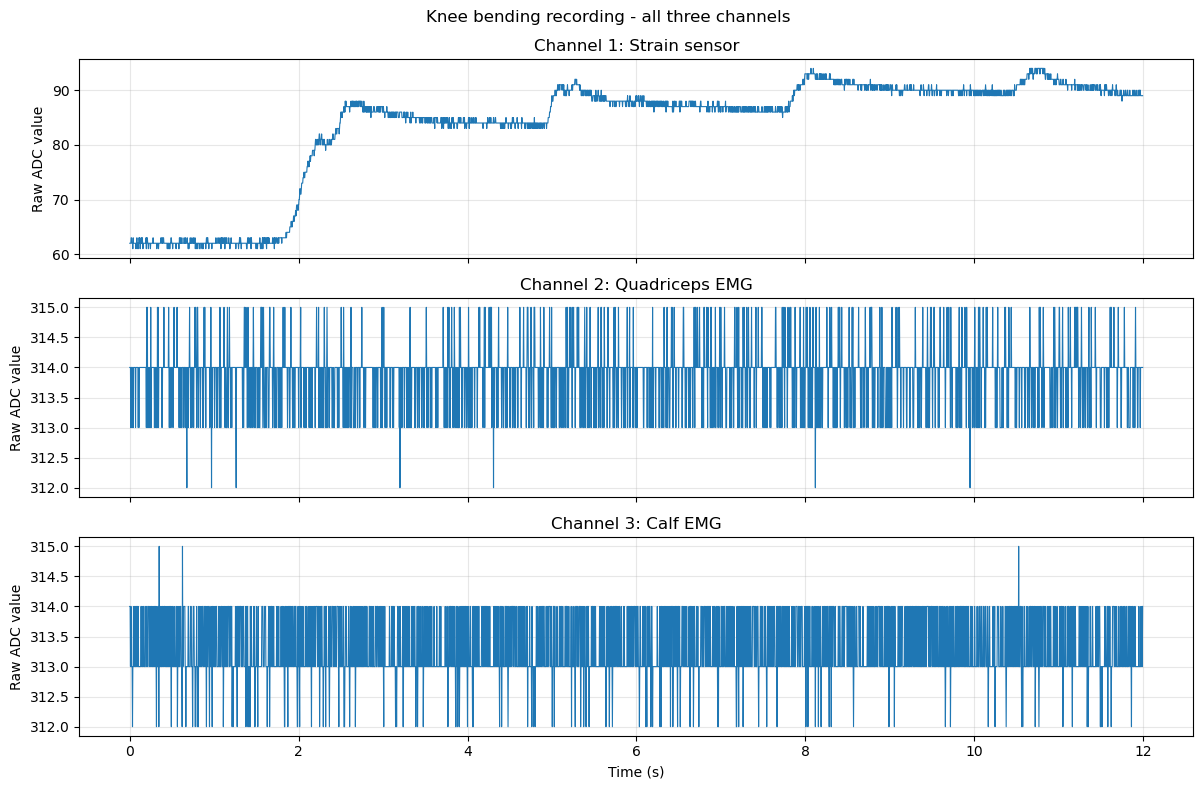

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Columns: strain sensor, quadriceps EMG, calf EMG (raw ADC values).
knee_data = np.loadtxt("ex1.2_check_1.txt", delimiter=",")
sampling_rate = 250  # Hz: 250 samples per second
time_s = np.arange(knee_data.shape[0]) / sampling_rate

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
channel_names = ["Strain sensor", "Quadriceps EMG", "Calf EMG"]
for channel, (ax, name) in enumerate(zip(axes, channel_names)):
    ax.plot(time_s[:3000], knee_data[:3000, channel], linewidth=0.8)
    ax.set_title(f"Channel {channel + 1}: {name}")
    ax.set_ylabel("Raw ADC value")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (s)")
fig.suptitle("Knee bending recording - all three channels")
fig.tight_layout()
plt.show()


### In case one wanted to see only the calf channel and the quad channel in the respective recordings, the code down here allows to do it

In [20]:
"""
# Load raw EMG test data
adc_quad = np.loadtxt("ex1.3_quad_20sec.txt", delimiter=",")
adc_calve = np.loadtxt("ex1.3_calve_20sec_clean.txt", delimiter=",")

# Extract raw EMG signals
emg_quad = adc_quad[:,1]
emg_calve = adc_calve[:,2]

# Plot quad EMG
plt.figure(figsize=(10, 4))
plt.plot(emg_quad, linewidth=0.8)
plt.xlabel("Sample Number", fontsize=14)
plt.ylabel("Raw EMG signals", fontsize=14)
plt.title("Quadriceps Muscle Activity", fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot calf EMG
plt.figure(figsize=(10, 4))
plt.plot(emg_calve, linewidth=0.8)
plt.xlabel("Sample Number", fontsize=14)
plt.ylabel("Raw EMG signals", fontsize=14)
plt.title("Calf Muscle Activity", fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.show()
"""

'\n# Load raw EMG test data\nadc_quad = np.loadtxt("ex1.3_quad_20sec.txt", delimiter=",")\nadc_calve = np.loadtxt("ex1.3_calve_20sec_clean.txt", delimiter=",")\n\n# Extract raw EMG signals\nemg_quad = adc_quad[:,1]\nemg_calve = adc_calve[:,2]\n\n# Plot quad EMG\nplt.figure(figsize=(10, 4))\nplt.plot(emg_quad, linewidth=0.8)\nplt.xlabel("Sample Number", fontsize=14)\nplt.ylabel("Raw EMG signals", fontsize=14)\nplt.title("Quadriceps Muscle Activity", fontsize=16)\nplt.grid(True)\nplt.tight_layout()\nplt.show()\n\n# Plot calf EMG\nplt.figure(figsize=(10, 4))\nplt.plot(emg_calve, linewidth=0.8)\nplt.xlabel("Sample Number", fontsize=14)\nplt.ylabel("Raw EMG signals", fontsize=14)\nplt.title("Calf Muscle Activity", fontsize=16)\nplt.grid(True)\nplt.tight_layout()\nplt.show()\n'

# Section 1.4

Test whatevre


### Movement Data Collection

In [21]:
adc_stand = np.loadtxt("ex1.4_stand_60sec_1.txt", delimiter=",")
adc_squat = np.loadtxt("ex1.4_squat_10times_2.txt", delimiter=",")
adc_toeraise = np.loadtxt("ex1.4_toeraise_1.txt", delimiter=",")
adc_kickback = np.loadtxt("ex1.4_kickback_1.txt", delimiter=",")
adc_kneeraise = np.loadtxt("ex1.4_kneeraise_1.txt", delimiter=",")

FileNotFoundError: ex1.4_toeraise_1.txt not found.

In [ ]:
""" 
# Plot all three sensor signals in one figure

def plot_movement(data, activity, filename):
    strain = adc_to_resistance(data[:,0])
    emg_quad = data[:,1]
    emg_calve = data[:,2]

    fig, ax = plt.subplots(3, 1, figsize=(10, 7))

    ax[0].plot(strain, linewidth=0.8)
    ax[0].set_ylabel("Resistance (Ohm)")
    ax[0].set_title("Strain Sensor")

    ax[1].plot(emg_quad, linewidth=0.8)
    ax[1].set_ylabel("Raw EMG Signal")
    ax[1].set_title("Quadriceps Muscle Activity")

    ax[2].plot(emg_calf, linewidth=0.8)
    ax[2].set_ylabel("Raw EMG Signal")
    ax[2].set_title("Calf Muscle Activity")
    ax[2].set_xlabel("Sample Number")

    for a in ax:
        a.grid(True)

    fig.suptitle(activity, fontsize=16)
    plt.tight_layout()
    plt.show()
"""

' \n# Plot all three sensor signals in one figure\n\ndef plot_movement(data, activity, filename):\n    strain = adc_to_resistance(data[:,0])\n    emg_quad = data[:,1]\n    emg_calve = data[:,2]\n\n    fig, ax = plt.subplots(3, 1, figsize=(10, 7))\n\n    ax[0].plot(strain, linewidth=0.8)\n    ax[0].set_ylabel("Resistance (Ohm)")\n    ax[0].set_title("Strain Sensor")\n\n    ax[1].plot(emg_quad, linewidth=0.8)\n    ax[1].set_ylabel("Raw EMG Signal")\n    ax[1].set_title("Quadriceps Muscle Activity")\n\n    ax[2].plot(emg_calf, linewidth=0.8)\n    ax[2].set_ylabel("Raw EMG Signal")\n    ax[2].set_title("Calf Muscle Activity")\n    ax[2].set_xlabel("Sample Number")\n\n    for a in ax:\n        a.grid(True)\n\n    fig.suptitle(activity, fontsize=16)\n    plt.tight_layout()\n    plt.show()\n'

In [ ]:
# Plots all three sensor signals in three seperate figures

def plot_movement(data, activity, filename):
    strain = adc_to_resistance(data[:, 0])
    emg_quad = data[:, 1]
    emg_calf = data[:, 2]

    # Strain sensor
    plt.figure(figsize=(10, 4))
    plt.plot(strain, linewidth=0.8)
    plt.xlabel("Sample Number", fontsize=14)
    plt.ylabel("Resistance (Ohm)", fontsize=14)
    plt.title(f"{activity} – Strain Sensor", fontsize=16)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Quadriceps EMG
    plt.figure(figsize=(10, 4))
    plt.plot(emg_quad, linewidth=0.8)
    plt.xlabel("Sample Number", fontsize=14)
    plt.ylabel("Raw EMG Signal", fontsize=14)
    plt.title(f"{activity} – Quadriceps EMG", fontsize=16)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Calf EMG
    plt.figure(figsize=(10, 4))
    plt.plot(emg_calf, linewidth=0.8)
    plt.xlabel("Sample Number", fontsize=14)
    plt.ylabel("Raw EMG Signal", fontsize=14)
    plt.title(f"{activity} – Calf EMG", fontsize=16)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

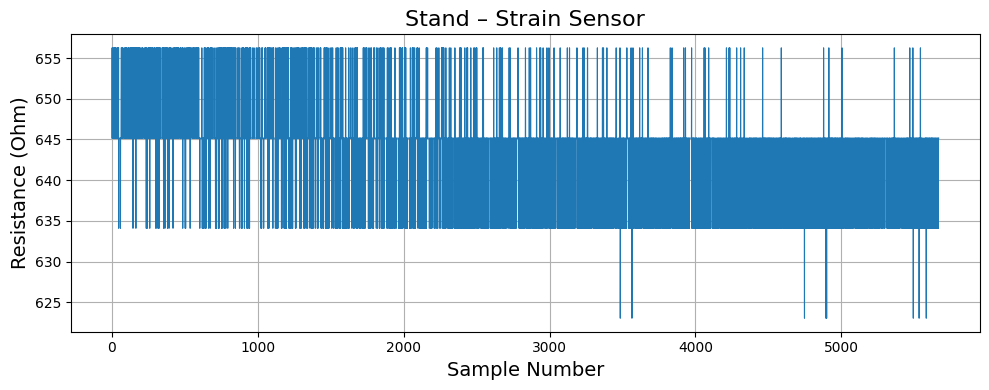

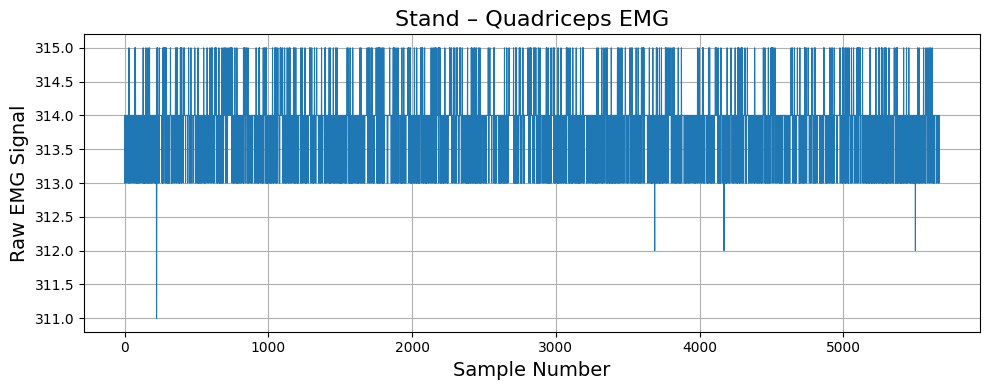

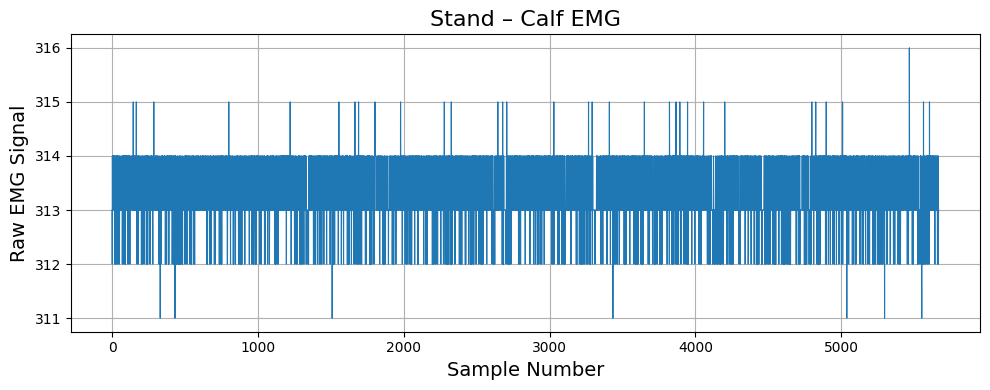

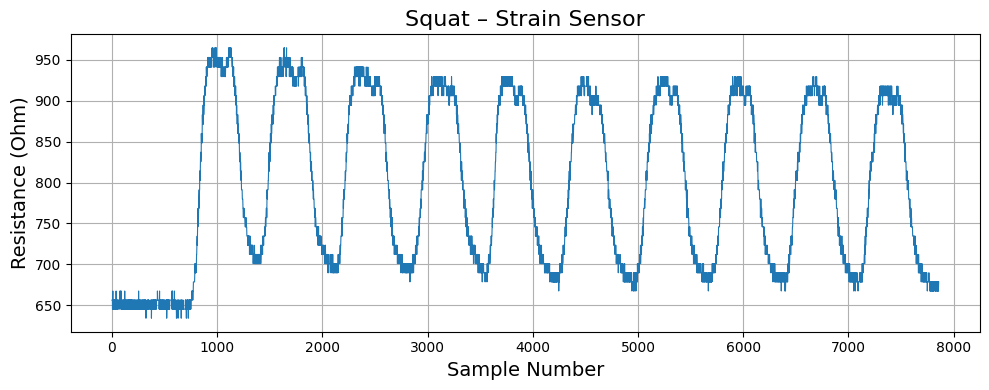

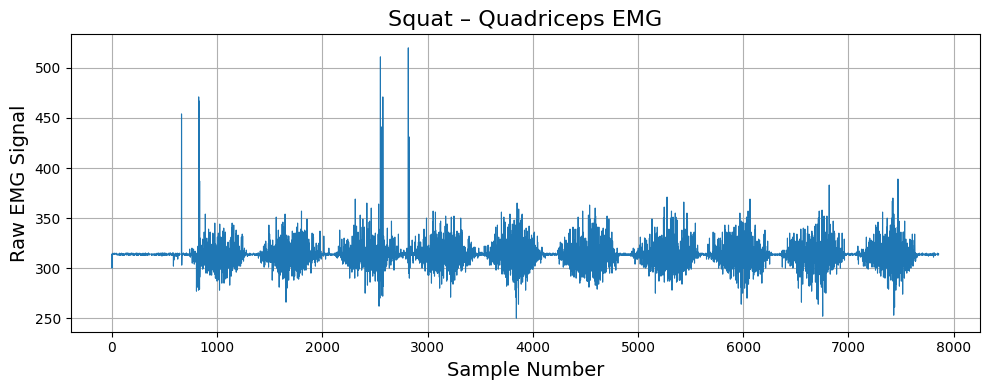

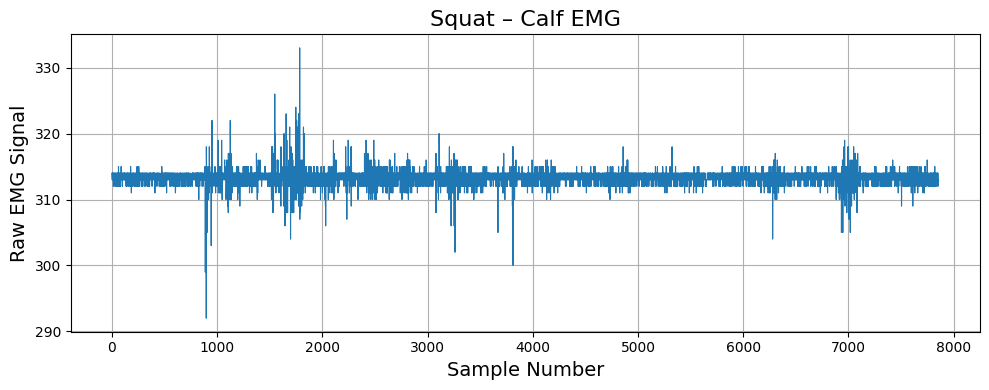

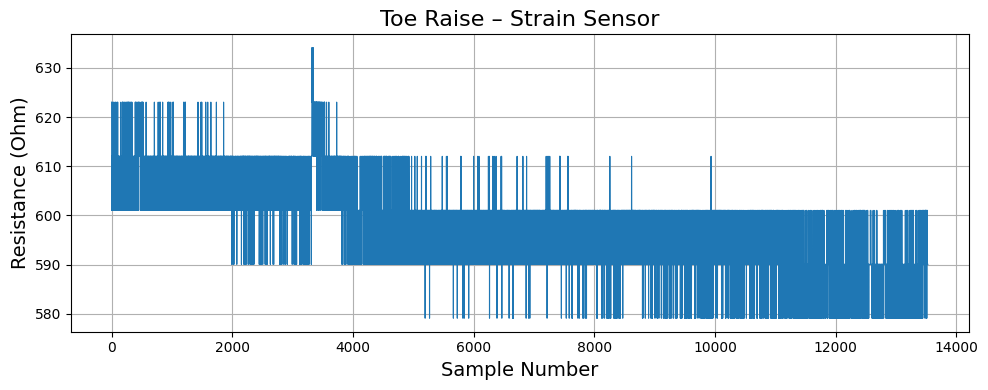

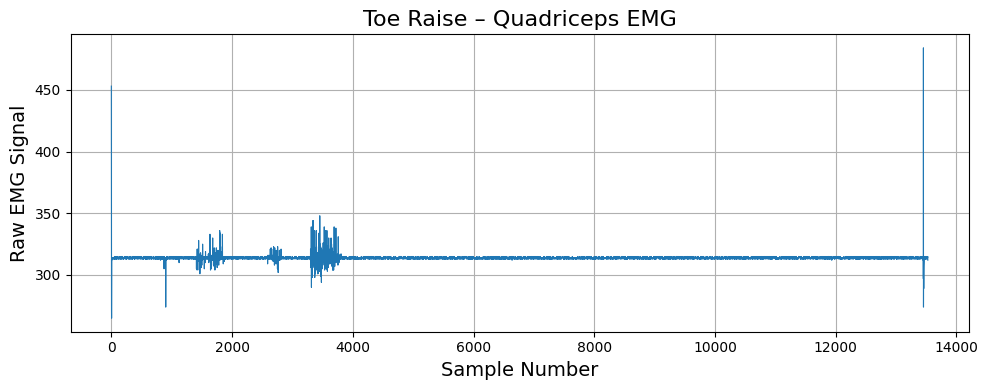

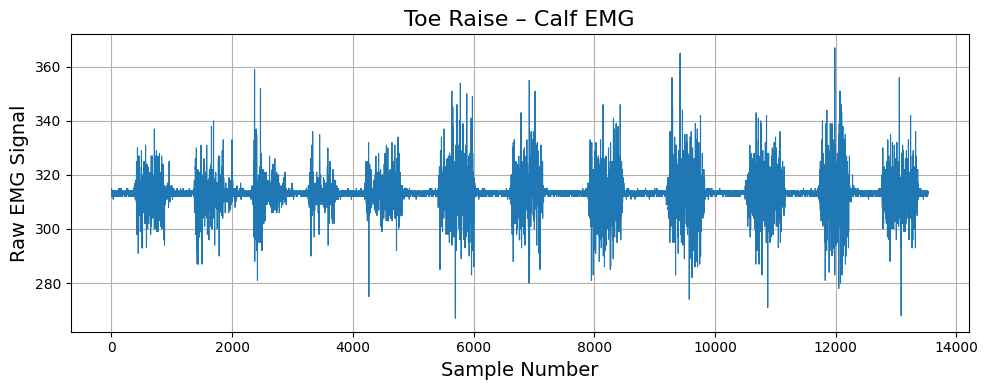

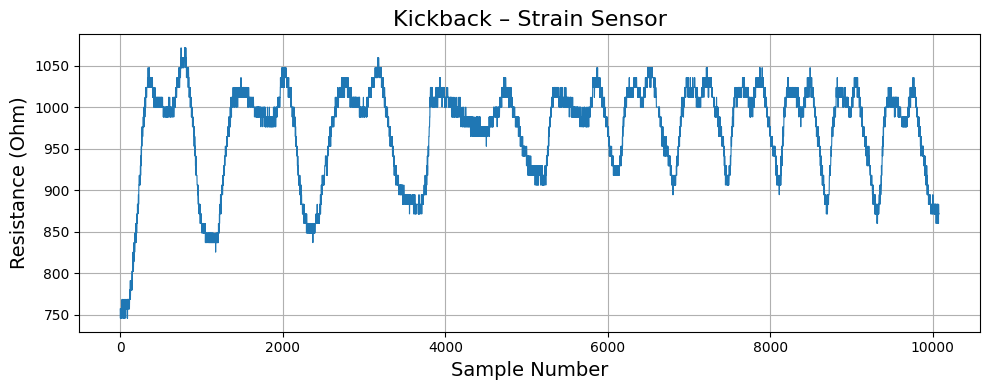

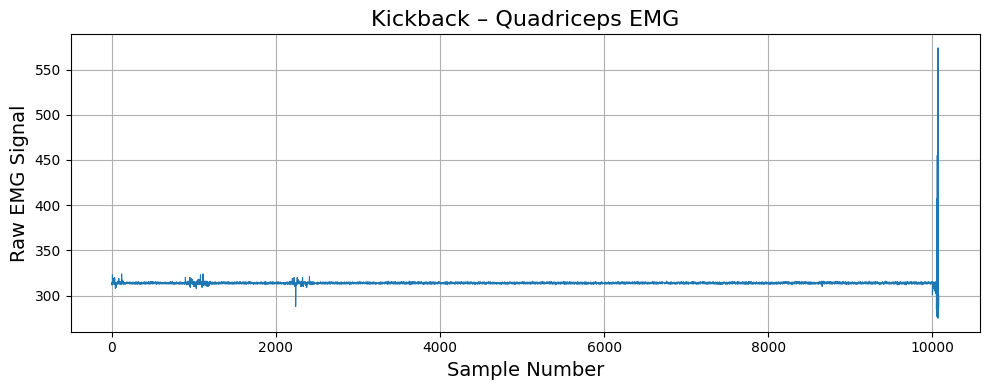

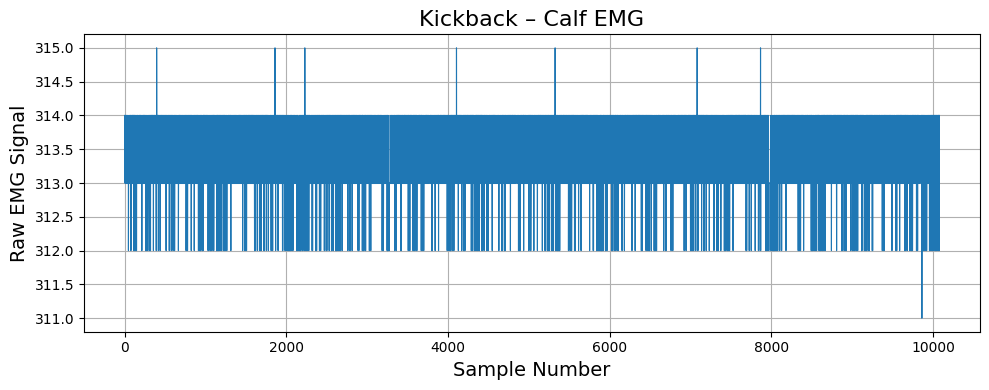

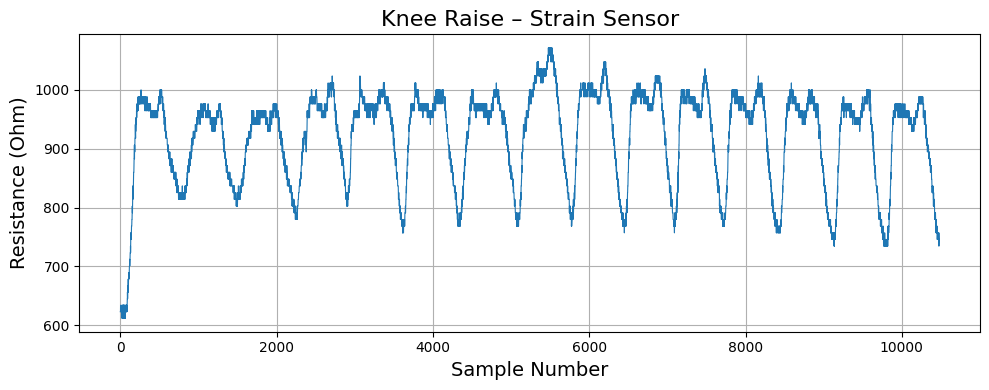

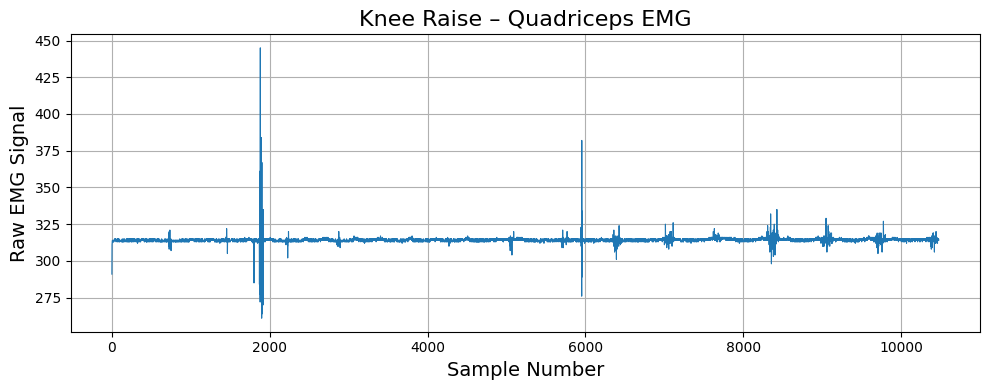

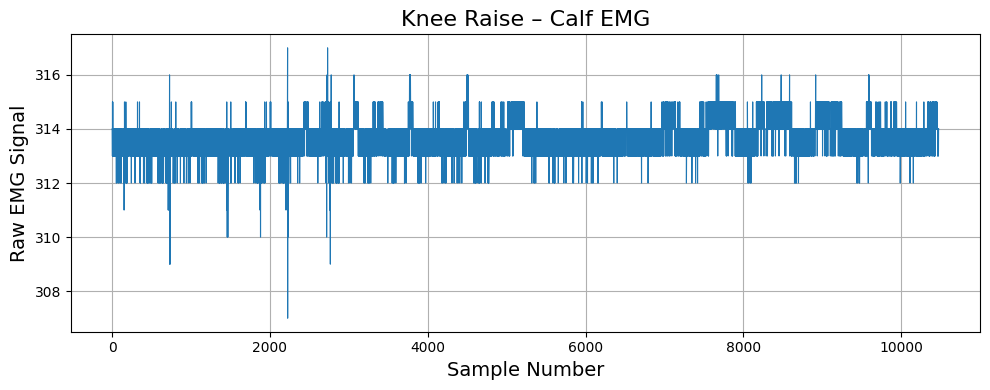

In [ ]:
plot_movement(adc_stand, "Stand", "stand.pdf")
plot_movement(adc_squat, "Squat", "squat.pdf")
plot_movement(adc_toeraise, "Toe Raise", "toeraise.pdf")
plot_movement(adc_kickback, "Kickback", "kickback.pdf")
plot_movement(adc_kneeraise, "Knee Raise", "kneeraise.pdf")

## Lab 2b - Data Processing

## Templates